# Engine Fault Detection from Sound — Pre-trained AST on KweriMoto

**Question:** Can a pre-trained audio model help a fleet / repair shop flag engines that need inspection,
by classifying a short recording as `healthy`, `engine_knock`, or `misfire`?

- **Model:** Audio Spectrogram Transformer (AST), `MIT/ast-finetuned-audioset-10-10-0.4593` (Hugging Face)
- **Dataset:** [KweriMoto Engine Sounds](https://huggingface.co/datasets/rayyyyy007/kwerimoto-engine-sounds) — 1,067 clips, predefined grouped splits
- **Protocol:** model selection on `validation`; `test` and `real_test` are evaluated **once**, at the end.

Sections: setup → data & leakage checks → success criteria → benchmark → baseline → diagnostics → experiments → final evaluation.

## 1. Setup

In [1]:
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
import torch
import torch.nn as nn
from huggingface_hub import snapshot_download
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, f1_score, recall_score
from transformers import ASTFeatureExtractor, ASTModel

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data" / "kwerimoto"
RESULTS_DIR = ROOT / "results"
CACHE_DIR = RESULTS_DIR / "cache"
FIG_DIR = RESULTS_DIR / "figures"
LOG_PATH = RESULTS_DIR / "experiment_log.csv"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

MODEL_ID = "MIT/ast-finetuned-audioset-10-10-0.4593"
LABELS = ["healthy", "engine_knock", "misfire"]
LABEL_TO_ID = {name: i for i, name in enumerate(LABELS)}
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def save_fig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")


set_seed()
print(f"torch {torch.__version__} | device: {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else ""))

torch 2.11.0+cu128 | device: cuda (NVIDIA GeForce RTX 5070 Ti Laptop GPU)


## 2. Data

In [2]:
# Downloads ~280 MB on first run; no-op afterwards.
snapshot_download("rayyyyy007/kwerimoto-engine-sounds", repo_type="dataset", local_dir=DATA_DIR)

manifest = pd.read_csv(DATA_DIR / "manifest.csv")
manifest["y"] = manifest["label"].map(LABEL_TO_ID)
manifest["path"] = manifest["file_name"].map(lambda f: str(DATA_DIR / f))

pd.crosstab([manifest["split"], manifest["label"]],
            [manifest["source_dataset"], manifest["synthetic"]],
            margins=True)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 1074 files:   0%|          | 0/1074 [00:00<?, ?it/s]

source_dataset          audioset huggingface revix        All
synthetic                  False       False False True      
split      label                                             
real_test  engine_knock       38           0     0    0    38
test       engine_knock       42           0     0   43    85
           healthy             0          12    41    0    53
           misfire             0          16     0    0    16
train      engine_knock      199           0     0  200   399
           healthy             0          56   190    0   246
           misfire             0          76     0    0    76
validation engine_knock       43           0     0   43    86
           healthy             0          12    40    0    52
           misfire             0          16     0    0    16
All                          322         188   271  286  1067

**Read this table carefully — it is the central limitation of the dataset.**

- Every `misfire` clip comes from one source (`huggingface`), and every AudioSet clip is `engine_knock`.
- Half of the knock clips are **synthetic**: an AudioSet knock sound mixed over a Revix car recording.
- `real_test` contains **only** real knocks — it measures how many real knocks we catch, not false alarms.

A model could score well by recognising *where a clip came from* rather than *what is wrong with the engine*.
Section 6 tests this directly.

### Leakage checks
Clips cut from the same recording must stay in one split. The synthetic knocks add a second path for leakage:
the AudioSet knock sound overlaid on a Revix clip is often also a real AudioSet clip in the dataset.

In [3]:
def splits_per(key, frame):
    return frame.groupby(key)["split"].nunique()

synthetic = manifest[manifest["synthetic"]]
audioset_split = manifest[manifest["source_dataset"] == "audioset"].set_index("original_file")["split"]
overlay_split = synthetic["knock_source"].map(audioset_split).dropna()

checks = {
    "groups spanning >1 split": int((splits_per("group", manifest) > 1).sum()),
    "source recordings spanning >1 split": int((splits_per("source_recording", manifest) > 1).sum()),
    "overlay knock sounds spanning >1 split": int((splits_per("knock_source", synthetic) > 1).sum()),
    "overlays whose knock clip sits in a different split":
        int((overlay_split != synthetic.loc[overlay_split.index, "split"]).sum()),
    "duplicate audio (sha256)": int(manifest["sha256"].duplicated().sum()),
}
for name, n in checks.items():
    print(f"{name:55s} {n}")
assert all(n == 0 for n in checks.values()), "split leakage detected"

groups spanning >1 split                                0
source recordings spanning >1 split                     0
overlay knock sounds spanning >1 split                  0
overlays whose knock clip sits in a different split     0
duplicate audio (sha256)                                0


### Load audio

In [4]:
def load_waveform(path):
    audio, sr = sf.read(path, dtype="float32")
    assert sr == 16_000 and audio.ndim == 1, (path, sr, audio.shape)
    return audio


waveforms = [load_waveform(p) for p in manifest["path"]]
manifest["seconds"] = [len(w) / 16_000 for w in waveforms]
manifest.groupby(["label", "source_dataset"])["seconds"].describe()[["count", "mean", "min", "max"]]

count      mean       min     max
label        source_dataset                                   
engine_knock audioset        322.0  9.854930  8.978000  10.000
             revix           286.0  7.407341  0.128000   9.984
healthy      huggingface      80.0  6.544609  1.216000  10.000
             revix           271.0  8.878669  0.400000  10.000
misfire      huggingface     108.0  6.958420  2.538687  10.000

## 3. Success criteria (defined before training)

> **Team: confirm or revise these before running experiments.** The assignment requires them up front.

| | Choice | Why |
|---|---|---|
| **Primary model metric** | **Fault recall** — mean recall over `engine_knock` and `misfire` | A missed fault risks engine damage; that error is far costlier than an extra inspection. |
| **Guardrail metric** | **Healthy false-alarm rate** — share of healthy clips flagged as faulty | Too many false alarms and technicians stop trusting the tool. |
| **Business success criterion** | Catch **≥ 85 %** of faulty engines while flagging **≤ 20 %** of healthy ones | Useful as a *triage* aid that prioritises inspections, not a replacement for a mechanic. |
| **Operational constraint** | Classify a 10 s clip in **< 1 s on a laptop CPU**; model small enough for a shop PC | A service writer would record on a phone/laptop, not a GPU server. |

We also report `fault_detected` (any fault predicted for a faulty clip, regardless of which fault),
since sending a misfire for inspection labelled "knock" still gets it inspected.

In [5]:
def evaluate(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    per_class = recall_score(y_true, y_pred, labels=[0, 1, 2], average=None, zero_division=0)
    flagged_share = lambda rows: (y_pred[rows] != 0).mean() if rows.any() else np.nan
    return {
        "fault_recall": per_class[1:].mean(),
        "knock_recall": per_class[1],
        "misfire_recall": per_class[2],
        "fault_detected": flagged_share(y_true != 0),
        "healthy_false_alarm": flagged_share(y_true == 0),
        "macro_f1": f1_score(y_true, y_pred, labels=[0, 1, 2], average="macro", zero_division=0),
        "accuracy": (y_true == y_pred).mean(),
    }


def log_run(run, change, reason, metrics, tradeoff):
    """Upserts one row of the assignment's experiment log (results/experiment_log.csv)."""
    row = {"run": run, "change": change, "reason": reason,
           **{k: round(float(v), 3) for k, v in metrics.items()}, "tradeoff": tradeoff}
    log = pd.read_csv(LOG_PATH) if LOG_PATH.exists() else pd.DataFrame()
    if len(log):
        log = log[log["run"] != run]
    log = pd.concat([log, pd.DataFrame([row])], ignore_index=True)
    log.to_csv(LOG_PATH, index=False)
    return log


split = {name: manifest.index[manifest["split"] == name].to_numpy()
         for name in ["train", "validation", "test", "real_test"]}
y = manifest["y"].to_numpy()
tr, va = split["train"], split["validation"]
synthetic_flag = manifest["synthetic"].to_numpy()


def val_metrics(val_pred):
    """evaluate() on the validation split, plus knock recall separately for real and synthetic knocks."""
    val_pred = np.asarray(val_pred)
    knock, synth = y[va] == LABEL_TO_ID["engine_knock"], synthetic_flag[va]
    return {
        **evaluate(y[va], val_pred),
        "real_knock_recall": (val_pred[knock & ~synth] == LABEL_TO_ID["engine_knock"]).mean(),
        "synthetic_knock_recall": (val_pred[knock & synth] == LABEL_TO_ID["engine_knock"]).mean(),
    }

## 4. Simple benchmark: majority class

In [6]:
majority = int(pd.Series(y[tr]).mode()[0])
benchmark = val_metrics(np.full(len(va), majority))
print(f"majority class = {LABELS[majority]}")
log_run("Benchmark", "Always predict majority class", "Floor any model must beat",
        benchmark, "No model; flags every engine as faulty").tail(1)

majority class = engine_knock


,run,change,reason,fault_recall,knock_recall,misfire_recall,fault_detected,healthy_false_alarm,macro_f1,accuracy,real_knock_recall,synthetic_knock_recall,tradeoff
4,Benchmark,Always predict majority class,Floor any model must beat,0.5,1.0,0.0,1.0,1.0,0.239,0.558,1.0,1.0,No model; flags every engine as faulty


**Note:** the majority class is `engine_knock`, so this benchmark has 100 % knock recall *and* a 100 % false-alarm
rate. That is why recall alone is not an adequate metric here — the false-alarm guardrail matters.

## 5. Baseline: frozen AST embeddings + linear head

AST is used as a fixed feature extractor: each clip → one 768-d embedding (`pooler_output`). Embeddings are
computed once and cached, so head-only experiments take seconds. Only the linear head (2,307 parameters) is trained.

In [7]:
feature_extractor = ASTFeatureExtractor.from_pretrained(MODEL_ID)
ast = ASTModel.from_pretrained(MODEL_ID).to(DEVICE).eval()
print(f"AST parameters: {sum(p.numel() for p in ast.parameters()) / 1e6:.1f} M")


@torch.inference_mode()
def embed(model, audios, batch_size=16, device=DEVICE):
    out = []
    for i in range(0, len(audios), batch_size):
        batch = feature_extractor(audios[i:i + batch_size], sampling_rate=16_000, return_tensors="pt")
        out.append(model(batch["input_values"].to(device)).pooler_output.float().cpu())
    return torch.cat(out).numpy()


emb_path = CACHE_DIR / "ast_pooler.npy"
if emb_path.exists():
    X = np.load(emb_path)
else:
    t0 = time.perf_counter()
    X = embed(ast, waveforms)
    print(f"embedded {len(X)} clips in {time.perf_counter() - t0:.1f}s")
    np.save(emb_path, X)
X.shape

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] ASTModel LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                         | Status     |  | 
----------------------------+------------+--+-
classifier.dense.bias       | UNEXPECTED |  | 
classifier.dense.weight     | UNEXPECTED |  | 
classifier.layernorm.bias   | UNEXPECTED |  | 
classifier.layernorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


AST parameters: 86.2 M


(1067, 768)

In [8]:
def train_head(X_train, y_train, X_val, y_val, lr=1e-3, epochs=150, batch_size=64,
               weight_decay=1e-4, class_weight=None, n_classes=len(LABELS), seed=SEED):
    """Trains a linear softmax head on fixed features; keeps the epoch with lowest validation loss."""
    set_seed(seed)
    mean, std = X_train.mean(0), X_train.std(0) + 1e-6
    to_t = lambda a: torch.tensor((a - mean) / std, dtype=torch.float32, device=DEVICE)
    Xt, Xv = to_t(X_train), to_t(X_val)
    yt = torch.tensor(y_train, device=DEVICE)
    yv = torch.tensor(y_val, device=DEVICE)

    head = nn.Linear(X_train.shape[1], n_classes).to(DEVICE)
    weight = None if class_weight is None else torch.tensor(class_weight, dtype=torch.float32, device=DEVICE)
    loss_fn = nn.CrossEntropyLoss(weight=weight)
    opt = torch.optim.AdamW(head.parameters(), lr=lr, weight_decay=weight_decay)

    history, best = [], (float("inf"), None, 0)
    for epoch in range(epochs):
        head.train()
        perm = torch.randperm(len(Xt), device=DEVICE)
        for i in range(0, len(Xt), batch_size):
            idx = perm[i:i + batch_size]
            opt.zero_grad()
            loss_fn(head(Xt[idx]), yt[idx]).backward()
            opt.step()
        head.eval()
        with torch.no_grad():
            train_loss = loss_fn(head(Xt), yt).item()
            val_logits = head(Xv)
            val_loss = loss_fn(val_logits, yv).item()
        val_metrics = evaluate(y_val, val_logits.argmax(1).cpu().numpy())
        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss, **val_metrics})
        if val_loss < best[0]:
            best = (val_loss, {k: v.clone() for k, v in head.state_dict().items()}, epoch)

    head.load_state_dict(best[1])
    head.eval()

    def predict_proba(X_new):
        with torch.no_grad():
            return torch.softmax(head(to_t(X_new)), 1).cpu().numpy()

    return predict_proba, pd.DataFrame(history), best[2]


def plot_history(history, best_epoch, title, save_as=None):
    fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.5))
    a.plot(history["train_loss"], label="train")
    a.plot(history["val_loss"], label="validation")
    a.set(title=f"{title}: loss", xlabel="epoch")
    b.plot(history["fault_recall"], label="fault recall")
    b.plot(history["healthy_false_alarm"], label="healthy false alarm")
    b.set(title=f"{title}: validation metrics", xlabel="epoch", ylim=(0, 1.02))
    for ax in (a, b):
        ax.axvline(best_epoch, color="grey", ls=":", label=f"kept epoch {best_epoch}")
        ax.legend()
    plt.tight_layout()
    if save_as:
        save_fig(save_as)
    plt.show()

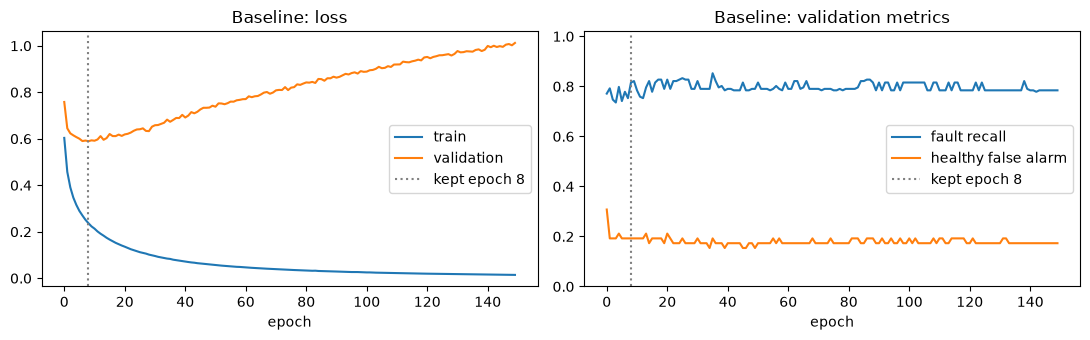

fault_recall              0.815
knock_recall              0.756
misfire_recall            0.875
fault_detected            0.833
healthy_false_alarm       0.192
macro_f1                  0.775
accuracy                  0.786
real_knock_recall         0.837
synthetic_knock_recall    0.674
dtype: float64

In [9]:
t0 = time.perf_counter()
baseline_proba, baseline_hist, baseline_best = train_head(X[tr], y[tr], X[va], y[va])
baseline_train_s = time.perf_counter() - t0
plot_history(baseline_hist, baseline_best, "Baseline", save_as="baseline_curves")

baseline_val_pred = baseline_proba(X[va]).argmax(1)
baseline = val_metrics(baseline_val_pred)
pd.Series(baseline).round(3)

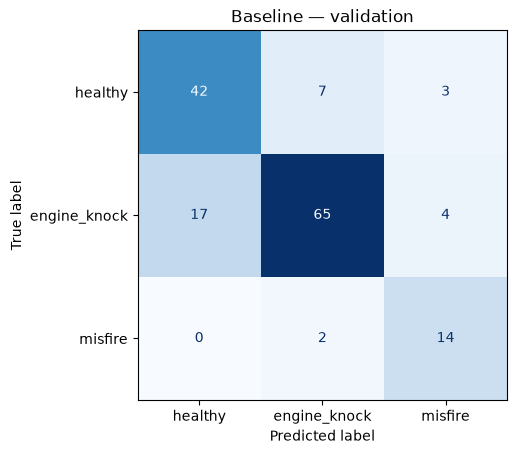

In [10]:
ConfusionMatrixDisplay(confusion_matrix(y[va], baseline_val_pred, labels=[0, 1, 2]),
                       display_labels=LABELS).plot(cmap="Blues", colorbar=False)
plt.title("Baseline — validation")
save_fig("baseline_confusion")
plt.show()

### Operational constraint: inference time
The head is negligible; inference cost is the AST forward pass. Measured on one 10 s clip at a time
(how a shop would use it), on GPU and on CPU.

In [11]:
def time_inference(device, n=10):
    model = ast.to(device)
    clip = [waveforms[i] for i in va[:n]]
    embed(model, clip[:1], batch_size=1, device=device)  # warm-up
    t0 = time.perf_counter()
    embed(model, clip, batch_size=1, device=device)
    return (time.perf_counter() - t0) / n * 1000


latency_ms = {"cpu": time_inference("cpu")}
if DEVICE == "cuda":
    latency_ms["cuda"] = time_inference("cuda")
ast.to(DEVICE)
print({k: f"{v:.0f} ms/clip" for k, v in latency_ms.items()})

{'cpu': '632 ms/clip', 'cuda': '59 ms/clip'}


In [12]:
log_run("Baseline", "Frozen AST embeddings + linear head (lr 1e-3)", "Establish reference",
        baseline,
        f"2.3k trainable params; head trains in {baseline_train_s:.0f}s; "
        f"{latency_ms['cpu']:.0f} ms/clip on CPU")

,run,change,reason,fault_recall,knock_recall,misfire_recall,fault_detected,healthy_false_alarm,macro_f1,accuracy,real_knock_recall,synthetic_knock_recall,tradeoff
0,Exp 1,Unfreeze top 2 AST layers (fine-tune),Adapt generic AudioSet features to engine faults,0.805,0.860,0.750,0.873,0.212,0.804,0.825,0.907,0.814,14.2M trainable params; trains in 2.3 min; shi...
1,Exp 2,Inverse-frequency class weights,Misfire is under-represented (76 of 721 train ...,0.860,0.721,1.000,0.833,0.192,0.765,0.779,0.814,0.628,No extra cost; shifts errors between classes
2,Exp 3,Drop synthetic knocks from training,Test whether synthetic data teaches the real k...,0.775,0.674,0.875,0.765,0.154,0.743,0.753,0.930,0.419,Less training data (521 vs 721 clips); no extr...
3,Benchmark,Always predict majority class,Floor any model must beat,0.500,1.000,0.000,1.000,1.000,0.239,0.558,1.000,1.000,No model; flags every engine as faulty
4,Baseline,Frozen AST embeddings + linear head (lr 1e-3),Establish reference,0.815,0.756,0.875,0.833,0.192,0.775,0.786,0.837,0.674,2.3k trainable params; head trains in 1s; 632 ...


### Validation errors (for error analysis)
Sorted by model confidence — confident mistakes are the most informative.

In [13]:
val_proba = baseline_proba(X[va])
errors = manifest.loc[va, ["file_name", "label", "source_dataset", "synthetic", "seconds"]].assign(
    predicted=[LABELS[i] for i in val_proba.argmax(1)],
    confidence=val_proba.max(1).round(3),
)
errors = errors[errors["label"] != errors["predicted"]].sort_values("confidence", ascending=False)
print(f"{len(errors)} validation errors")
errors.to_csv(RESULTS_DIR / "baseline_val_errors.csv")
errors

33 validation errors


,file_name,label,source_dataset,synthetic,seconds,predicted,confidence
961,prepared/validation/engine_knock/revix_car_kno...,engine_knock,revix,True,4.128000,healthy,0.968
926,prepared/validation/engine_knock/audioset_9wGJ...,engine_knock,audioset,False,10.000000,healthy,0.953
996,prepared/validation/engine_knock/revix_car_kno...,engine_knock,revix,True,9.984000,healthy,0.945
1008,prepared/validation/healthy/hf_healthy_059.wav,healthy,huggingface,False,6.762688,misfire,0.922
968,prepared/validation/engine_knock/revix_car_kno...,engine_knock,revix,True,4.951000,healthy,0.911
976,prepared/validation/engine_knock/revix_car_kno...,engine_knock,revix,True,4.128000,healthy,0.876
986,prepared/validation/engine_knock/revix_car_kno...,engine_knock,revix,True,9.984000,healthy,0.855
994,prepared/validation/engine_knock/revix_car_kno...,engine_knock,revix,True,9.554000,healthy,0.840
989,prepared/validation/engine_knock/revix_car_kno...,engine_knock,revix,True,9.238000,misfire,0.834
975,prepared/validation/engine_knock/revix_car_kno...,engine_knock,revix,True,1.859000,healthy,0.805


## 6. Diagnostic: can the embeddings identify the *recording source*?

If the same frozen embeddings + linear head can predict which dataset a clip came from almost perfectly,
then source is a usable shortcut, and high fault accuracy does not by itself show the model hears the fault.
This is a diagnostic, not one of the three experiments.

In [14]:
source_names = sorted(manifest["source_dataset"].unique())
source_y = manifest["source_dataset"].map({s: i for i, s in enumerate(source_names)}).to_numpy()


def source_probe(rows_train, rows_val):
    # The per-epoch fault metrics in the returned history are meaningless here; only the predictor is used.
    proba, _, _ = train_head(X[rows_train], source_y[rows_train], X[rows_val], source_y[rows_val],
                             n_classes=len(source_names))
    return (proba(X[rows_val]).argmax(1) == source_y[rows_val]).mean()


print(f"source accuracy (validation): {source_probe(tr, va):.3f}  "
      f"(chance ≈ {pd.Series(source_y[va]).value_counts(normalize=True).max():.3f})")

# Harder case: among healthy clips only, the label can't help — does the source still show?
tr_h, va_h = tr[y[tr] == 0], va[y[va] == 0]
print(f"source accuracy, healthy clips only: {source_probe(tr_h, va_h):.3f}  "
      f"(chance ≈ {pd.Series(source_y[va_h]).value_counts(normalize=True).max():.3f})")

source accuracy (validation): 0.948  (chance ≈ 0.539)


source accuracy, healthy clips only: 0.981  (chance ≈ 0.769)


## 7. Controlled experiments (one change at a time vs. baseline)

Each experiment changes exactly one thing relative to the baseline (frozen AST + linear head, lr 1e-3, epoch kept by
lowest validation loss). All are judged on the validation split.

### Experiment 1 — partial fine-tuning (frozen → top 2 AST layers trainable)

**Change:** unfreeze the last 2 of AST's 12 transformer layers (plus its final layer norm) and train them together
with the head on the spectrograms. Backbone lr 2e-5, head lr 1e-3, 10 epochs, bf16 autocast.

**Expectation:** AudioSet features are generic ("engine", "vehicle"); letting the top layers adapt should help
separate a knock mixed into engine noise from the clean engine — i.e. raise synthetic-knock recall — at the cost of
minutes instead of seconds of training and a 345 MB fine-tuned model to ship instead of a 9 KB head.

In [15]:
# Spectrogram inputs (1024 frames x 128 mel bins) computed once and cached as fp16.
inputs_path = CACHE_DIR / "ast_input_values.npy"
if inputs_path.exists():
    inputs = np.load(inputs_path)
else:
    inputs = np.concatenate([
        feature_extractor(waveforms[i:i + 64], sampling_rate=16_000, return_tensors="np")["input_values"]
        for i in range(0, len(waveforms), 64)
    ]).astype(np.float16)
    np.save(inputs_path, inputs)


class ASTClassifier(nn.Module):
    def __init__(self, n_trainable_layers):
        super().__init__()
        self.ast = ASTModel.from_pretrained(MODEL_ID)
        self.head = nn.Linear(self.ast.config.hidden_size, len(LABELS))
        for p in self.ast.parameters():
            p.requires_grad = False
        for module in [*self.ast.layers[-n_trainable_layers:], self.ast.layernorm]:
            for p in module.parameters():
                p.requires_grad = True

    def forward(self, x):
        return self.head(self.ast(x).pooler_output)


def finetune(n_trainable_layers=2, epochs=10, batch_size=16, backbone_lr=2e-5, head_lr=1e-3,
             rows_train=tr, seed=SEED):
    """Fine-tunes the top AST layers + head; keeps the epoch with lowest validation loss (as train_head does)."""
    set_seed(seed)
    model = ASTClassifier(n_trainable_layers).to(DEVICE)
    trainable = {n for n, p in model.named_parameters() if p.requires_grad}
    opt = torch.optim.AdamW([
        {"params": [p for p in model.ast.parameters() if p.requires_grad], "lr": backbone_lr},
        {"params": model.head.parameters(), "lr": head_lr},
    ], weight_decay=1e-4)
    loss_fn = nn.CrossEntropyLoss()

    def logits(rows):
        model.eval()
        out = []
        with torch.no_grad(), torch.autocast(DEVICE, dtype=torch.bfloat16):
            for i in range(0, len(rows), 32):
                x = torch.from_numpy(inputs[rows[i:i + 32]]).to(DEVICE).float()
                out.append(model(x).float().cpu())
        return torch.cat(out)

    history, best = [], (float("inf"), None, 0)
    for epoch in range(epochs):
        model.train()
        order = np.random.permutation(rows_train)
        for i in range(0, len(order), batch_size):
            idx = order[i:i + batch_size]
            x = torch.from_numpy(inputs[idx]).to(DEVICE).float()
            with torch.autocast(DEVICE, dtype=torch.bfloat16):
                loss = loss_fn(model(x), torch.tensor(y[idx], device=DEVICE))
            opt.zero_grad()
            loss.backward()
            opt.step()
        train_loss = loss_fn(logits(rows_train), torch.tensor(y[rows_train])).item()
        val_logits = logits(va)
        val_loss = loss_fn(val_logits, torch.tensor(y[va])).item()
        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,
                        **evaluate(y[va], val_logits.argmax(1).numpy())})
        print(f"epoch {epoch}: train {train_loss:.3f}  val {val_loss:.3f}  "
              f"fault recall {history[-1]['fault_recall']:.3f}")
        if val_loss < best[0]:
            state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items() if k in trainable}
            best = (val_loss, state, epoch)

    model.load_state_dict(best[1], strict=False)
    predict_proba = lambda rows: torch.softmax(logits(rows), 1).numpy()
    n_trainable = sum(p.numel() for n, p in model.named_parameters() if n in trainable)
    return model, predict_proba, pd.DataFrame(history), best[2], n_trainable

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] ASTModel LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                         | Status     |  | 
----------------------------+------------+--+-
classifier.dense.bias       | UNEXPECTED |  | 
classifier.dense.weight     | UNEXPECTED |  | 
classifier.layernorm.bias   | UNEXPECTED |  | 
classifier.layernorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


epoch 0: train 0.260  val 0.465  fault recall 0.834


epoch 1: train 0.136  val 0.363  fault recall 0.811


epoch 2: train 0.086  val 0.354  fault recall 0.805


epoch 3: train 0.064  val 0.365  fault recall 0.899


... (2 outputs left out)

epoch 6: train 0.033  val 0.393  fault recall 0.891


epoch 7: train 0.027  val 0.397  fault recall 0.868


epoch 8: train 0.022  val 0.415  fault recall 0.879


epoch 9: train 0.019  val 0.401  fault recall 0.842


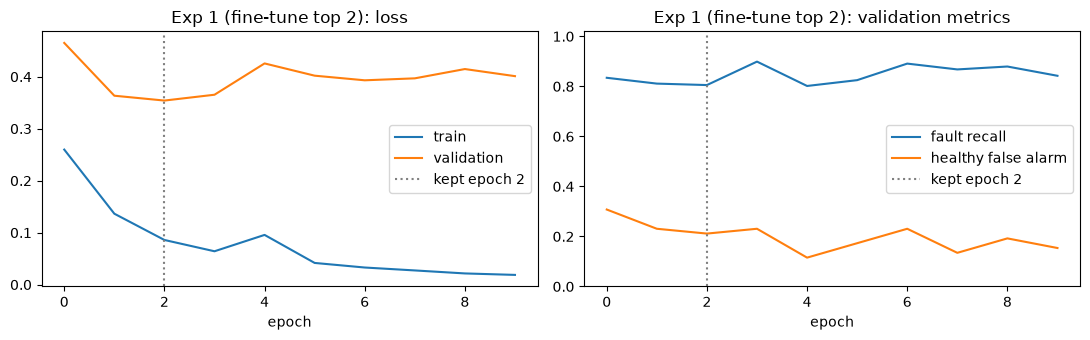

,run,change,reason,fault_recall,knock_recall,misfire_recall,fault_detected,healthy_false_alarm,macro_f1,accuracy,real_knock_recall,synthetic_knock_recall,tradeoff
3,Baseline,Frozen AST embeddings + linear head (lr 1e-3),Establish reference,0.815,0.756,0.875,0.833,0.192,0.775,0.786,0.837,0.674,2.3k trainable params; head trains in 1s; 632 ...
4,Exp 1,Unfreeze top 2 AST layers (fine-tune),Adapt generic AudioSet features to engine faults,0.805,0.860,0.750,0.873,0.212,0.804,0.825,0.907,0.814,14.2M trainable params; trains in 2.3 min; shi...


In [16]:
t0 = time.perf_counter()
ft_model, ft_proba, ft_hist, ft_best, ft_params = finetune(n_trainable_layers=2)
ft_train_s = time.perf_counter() - t0
plot_history(ft_hist, ft_best, "Exp 1 (fine-tune top 2)", save_as="exp1_curves")

exp1 = val_metrics(ft_proba(va).argmax(1))
log_run("Exp 1", "Unfreeze top 2 AST layers (fine-tune)", "Adapt generic AudioSet features to engine faults",
        exp1, f"{ft_params / 1e6:.1f}M trainable params; trains in {ft_train_s / 60:.1f} min; "
              f"ships a 345 MB model instead of a 9 KB head; same inference cost").tail(2)

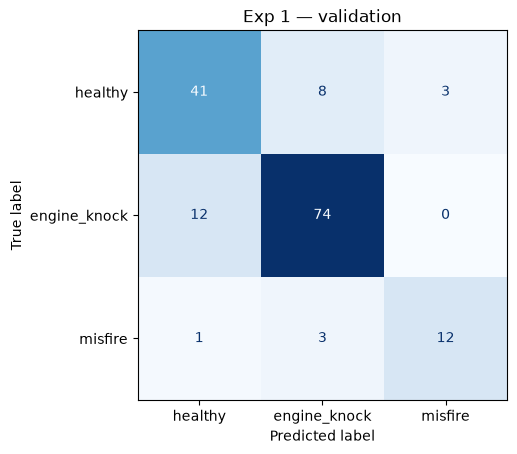

In [17]:
ConfusionMatrixDisplay(confusion_matrix(y[va], ft_proba(va).argmax(1), labels=[0, 1, 2]),
                       display_labels=LABELS).plot(cmap="Blues", colorbar=False)
plt.title("Exp 1 — validation")
plt.show()

**Result (draft — team to verify against the numbers above):** the primary metric did **not** improve
(fault recall ≈ 0.81 vs 0.82). Knock recall rose (≈ 0.76 → 0.86), with the biggest gain on *synthetic* knocks
(≈ 0.67 → 0.81), but misfire recall fell (0.875 → 0.75 — two more of 16 clips missed). Validation loss bottoms out
at epoch 2 and fault recall swings ±0.05 from epoch to epoch, so the model overfits fast and differences of 1–2
clips are within noise. Cost: ~6,000× more trainable parameters, minutes instead of a second to train, and a full
345 MB model to deploy.

**Learned:** with ~700 training clips, adapting the backbone mainly helped the class with the most data and did not
pay for its cost on our primary metric. A candidate for the "unsuccessful experiment" write-up.

### Experiment 2 — class-weighted loss

**Change:** weight the cross-entropy loss by inverse class frequency (misfire has 76 training clips vs. 399 knocks).
Everything else as baseline.

**Expectation:** higher misfire recall; possibly more healthy clips flagged as faulty. Misfire recall is already
0.875 on 16 validation clips (= 2 errors), so there is little room to show a gain.

{'healthy': np.float64(0.98), 'engine_knock': np.float64(0.6), 'misfire': np.float64(3.16)}


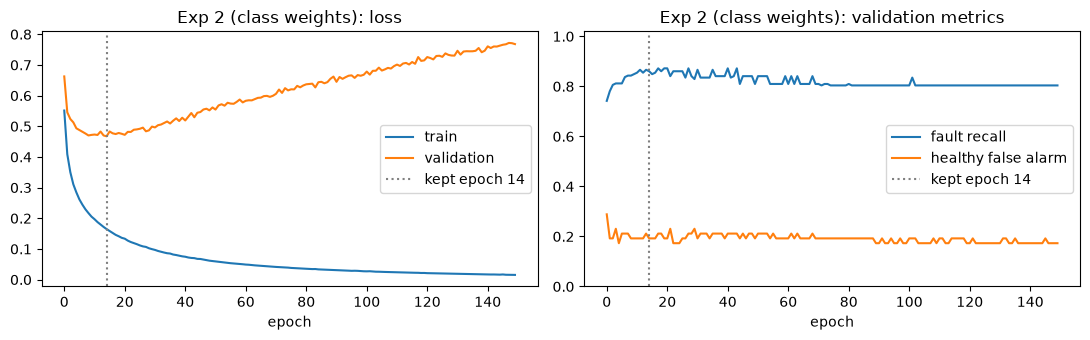

,run,change,reason,fault_recall,knock_recall,misfire_recall,fault_detected,healthy_false_alarm,macro_f1,accuracy,real_knock_recall,synthetic_knock_recall,tradeoff
3,Exp 1,Unfreeze top 2 AST layers (fine-tune),Adapt generic AudioSet features to engine faults,0.805,0.860,0.75,0.873,0.212,0.804,0.825,0.907,0.814,14.2M trainable params; trains in 2.3 min; shi...
4,Exp 2,Inverse-frequency class weights,Misfire is under-represented (76 of 721 train ...,0.860,0.721,1.00,0.833,0.192,0.765,0.779,0.814,0.628,No extra cost; shifts errors between classes


In [18]:
counts = np.bincount(y[tr], minlength=len(LABELS))
class_weight = len(tr) / (len(LABELS) * counts)
print(dict(zip(LABELS, class_weight.round(2))))

exp2_proba, exp2_hist, exp2_best = train_head(X[tr], y[tr], X[va], y[va], class_weight=class_weight)
plot_history(exp2_hist, exp2_best, "Exp 2 (class weights)")
exp2 = val_metrics(exp2_proba(X[va]).argmax(1))
log_run("Exp 2", "Inverse-frequency class weights", "Misfire is under-represented (76 of 721 train clips)",
        exp2, "No extra cost; shifts errors between classes").tail(2)

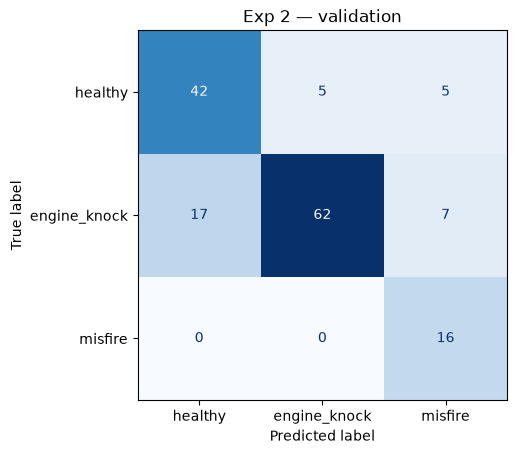

In [19]:
ConfusionMatrixDisplay(confusion_matrix(y[va], exp2_proba(X[va]).argmax(1), labels=[0, 1, 2]),
                       display_labels=LABELS).plot(cmap="Blues", colorbar=False)
plt.title("Exp 2 — validation")
save_fig("exp2_confusion")
plt.show()

**Result (draft):** misfire recall rose to 16/16 and fault recall to ≈ 0.86 — the only run that meets both
validation targets (≥ 0.85 fault recall, ≤ 0.20 false alarms). Knock recall dipped slightly (≈ 0.76 → 0.72):
the weights moved errors from misfire to knock rather than removing them. The gain is **two clips**, so treat it as
"consistent with the hypothesis", not proof.

**Caution:** every misfire clip comes from one source; part of what the weights amplify may be that source.

### Experiment 3 — train without synthetic knocks

**Change:** drop the 200 synthetic knock clips from training (validation unchanged, so it still contains 43 synthetic
knocks). Everything else as baseline.

**Expectation:** if synthetic knocks teach the real knock sound, removing them should lower recall on *real* knocks.
If they mostly teach "Revix recording + overlay", real-knock recall should hold while synthetic-knock recall falls.

**Caveat:** this also changes the class balance (knock drops from 55 % to 38 % of training clips), so it is not a
perfectly clean single-variable change — note this when interpreting.

training clips: 721 -> 521 {'healthy': np.int64(246), 'engine_knock': np.int64(199), 'misfire': np.int64(76)}


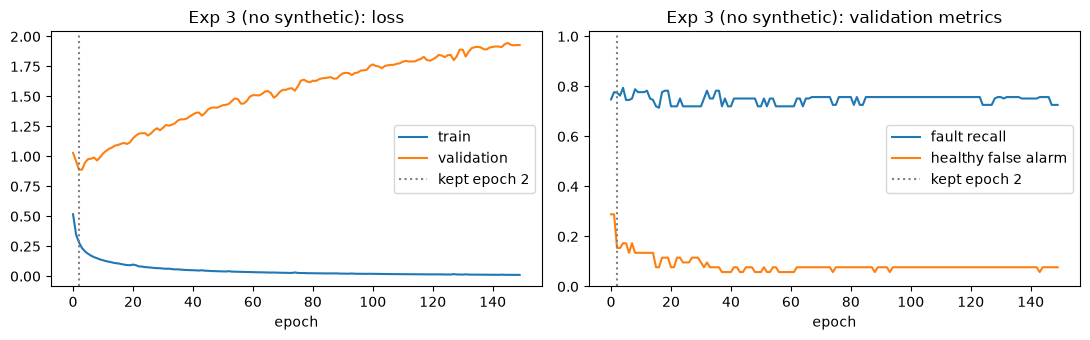

,run,change,reason,fault_recall,knock_recall,misfire_recall,fault_detected,healthy_false_alarm,macro_f1,accuracy,real_knock_recall,synthetic_knock_recall,tradeoff
3,Exp 2,Inverse-frequency class weights,Misfire is under-represented (76 of 721 train ...,0.860,0.721,1.000,0.833,0.192,0.765,0.779,0.814,0.628,No extra cost; shifts errors between classes
4,Exp 3,Drop synthetic knocks from training,Test whether synthetic data teaches the real k...,0.775,0.674,0.875,0.765,0.154,0.743,0.753,0.930,0.419,Less training data (521 vs 721 clips); no extr...


In [20]:
tr_real = tr[~synthetic_flag[tr]]
print(f"training clips: {len(tr)} -> {len(tr_real)}",
      dict(zip(LABELS, np.bincount(y[tr_real], minlength=len(LABELS)))))

exp3_proba, exp3_hist, exp3_best = train_head(X[tr_real], y[tr_real], X[va], y[va])
plot_history(exp3_hist, exp3_best, "Exp 3 (no synthetic)")
exp3 = val_metrics(exp3_proba(X[va]).argmax(1))
log_run("Exp 3", "Drop synthetic knocks from training", "Test whether synthetic data teaches the real knock sound",
        exp3, "Less training data (521 vs 721 clips); no extra cost").tail(2)

**Result (draft):** real-knock recall went **up** (≈ 0.84 → 0.93) while synthetic-knock recall collapsed
(≈ 0.67 → 0.42), and fault recall fell overall. Removing synthetic knocks did not hurt real-knock detection — so the
synthetic clips were not what taught the model the real knock sound.

**But read the real-knock number sceptically:** in this dataset *every* AudioSet clip is a knock, and Section 6 showed
the embeddings identify the source with ~95 % accuracy. A model can reach high real-knock recall by recognising
"YouTube/AudioSet audio" alone. This experiment therefore sharpens the central limitation rather than resolving it:
the data cannot separate *knock* from *source*.

## Experiment comparison

,run,change,reason,fault_recall,knock_recall,misfire_recall,fault_detected,healthy_false_alarm,macro_f1,accuracy,real_knock_recall,synthetic_knock_recall,tradeoff
0,Benchmark,Always predict majority class,Floor any model must beat,0.500,1.000,0.000,1.000,1.000,0.239,0.558,1.000,1.000,No model; flags every engine as faulty
1,Baseline,Frozen AST embeddings + linear head (lr 1e-3),Establish reference,0.815,0.756,0.875,0.833,0.192,0.775,0.786,0.837,0.674,2.3k trainable params; head trains in 1s; 632 ...
2,Exp 1,Unfreeze top 2 AST layers (fine-tune),Adapt generic AudioSet features to engine faults,0.805,0.860,0.750,0.873,0.212,0.804,0.825,0.907,0.814,14.2M trainable params; trains in 2.3 min; shi...
3,Exp 2,Inverse-frequency class weights,Misfire is under-represented (76 of 721 train ...,0.860,0.721,1.000,0.833,0.192,0.765,0.779,0.814,0.628,No extra cost; shifts errors between classes
4,Exp 3,Drop synthetic knocks from training,Test whether synthetic data teaches the real k...,0.775,0.674,0.875,0.765,0.154,0.743,0.753,0.930,0.419,Less training data (521 vs 721 clips); no extr...


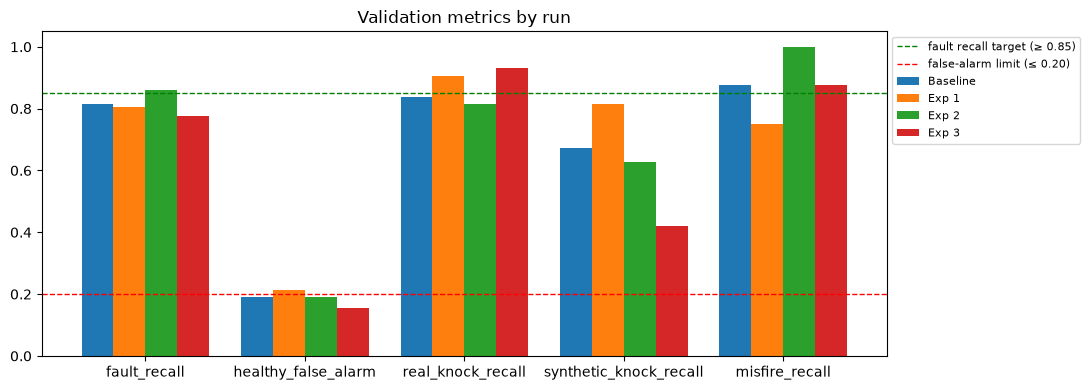

In [21]:
log = pd.read_csv(LOG_PATH)
display(log)

runs = log[log["run"] != "Benchmark"]
metrics = ["fault_recall", "healthy_false_alarm", "real_knock_recall", "synthetic_knock_recall", "misfire_recall"]
ax = runs.set_index("run")[metrics].T.plot.bar(figsize=(11, 4), rot=0, width=0.8)
ax.axhline(0.85, color="green", ls="--", lw=1, label="fault recall target (≥ 0.85)")
ax.axhline(0.20, color="red", ls="--", lw=1, label="false-alarm limit (≤ 0.20)")
ax.set(ylim=(0, 1.05), title="Validation metrics by run")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8)
plt.tight_layout()
save_fig("comparison")
plt.show()

## 9. Additional analyses: is the model hearing the fault, or the recording source?

These go beyond the three required experiments. All use the validation split only.

### 9a. Within-source tests
The only comparisons in this dataset where the recording source is held fixed:

- **Knock vs healthy, Revix only** — healthy Revix car recordings vs Revix recordings with a knock overlaid.
- **Misfire vs healthy, Hugging Face only** — both classes come from the same source.

Validation sizes: 43 knock / 40 healthy (Revix), 16 misfire / 12 healthy (HF) — small, so differences of a few
hundredths are noise. Metric: ROC AUC of the model's fault probability (0.5 = coin flip, 1.0 = perfect ranking). If a model's overall
scores are good but its within-source AUC is near 0.5, it was relying on the source.

In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

source = manifest["source_dataset"].to_numpy()
WITHIN_SOURCE = {  # name -> (source, fault): pairs where healthy clips and the fault share a recording source
    "AUC knock|Revix": ("revix", "engine_knock"),
    "AUC misfire|HF": ("huggingface", "misfire"),
}


def within_source(val_proba):
    """ROC AUC of P(fault) for fault vs healthy validation clips from a single recording source."""
    out = {}
    for name, (src, fault) in WITHIN_SOURCE.items():
        rows = (source[va] == src) & np.isin(y[va], [0, LABEL_TO_ID[fault]])
        out[name] = roc_auc_score(y[va][rows] == LABEL_TO_ID[fault], val_proba[rows, LABEL_TO_ID[fault]])
    return out


def probe(features, rows_train, rows_val, target):
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
    clf.fit(features[rows_train], target[rows_train])
    return clf.predict_proba(features[rows_val])[:, 1]


# Reference: a probe trained *within* each source shows whether the AST features carry the fault at all.
within_trained = {}
for name, (src, fault) in WITHIN_SOURCE.items():
    pick = lambda rows: rows[(source[rows] == src) & np.isin(y[rows], [0, LABEL_TO_ID[fault]])]
    rtr, rva = pick(tr), pick(va)
    is_fault = y == LABEL_TO_ID[fault]
    within_trained[name] = roc_auc_score(is_fault[rva], probe(X, rtr, rva, is_fault))

within_table = pd.DataFrame({
    "Baseline": within_source(baseline_proba(X[va])),
    "Exp 1 (fine-tune)": within_source(ft_proba(va)),
    "Exp 2 (class weights)": within_source(exp2_proba(X[va])),
    "Exp 3 (no synthetic)": within_source(exp3_proba(X[va])),
    "Probe trained within source": within_trained,
}).T.round(3)
within_table.to_csv(RESULTS_DIR / "within_source.csv")
within_table

,AUC knock|Revix,AUC misfire|HF
Baseline,0.865,0.859
Exp 1 (fine-tune),0.906,0.854
Exp 2 (class weights),0.873,0.891
Exp 3 (no synthetic),0.701,0.781
Probe trained within source,0.876,0.938


**Result (draft):** with the source held fixed, the baseline still ranks faulty above healthy clips well
(AUC ≈ 0.87 for knock within Revix, ≈ 0.86 for misfire within Hugging Face). This is the strongest evidence so far
that the AST features carry *fault* information, not only source information.

Two caveats limit how far this goes: (1) Revix "knocks" are an AudioSet knock sound overlaid on the recording, so
this shows the model can hear an overlaid knock, not a knock produced by that engine; (2) the Hugging Face test has
only 28 clips. Note that Exp 3 (no synthetic knocks) drops to ≈ 0.70 within Revix: without the overlays, the
model's idea of "knock" leans more on AudioSet-like audio — the shortcut gets used when it is available.

### 9b. Zero-shot baselines (no training on our data)

- **AST's own AudioSet classifier** has an `Engine knocking` output. If it scores AudioSet knocks far better than
  Revix knocks, that is consistent with AST having seen these AudioSet clips (with labels) during pre-training.
- **CLAP** (`laion/clap-htsat-unfused`) compares audio with text prompts, so it can attempt all three classes.
  CLAP expects 48 kHz audio; our clips are upsampled from 16 kHz, so it sees no content above 8 kHz.

In [23]:
from transformers import ASTForAudioClassification, ClapModel, ClapProcessor
import torchaudio.functional as AF

ast_cls = ASTForAudioClassification.from_pretrained(MODEL_ID).to(DEVICE).eval()
knock_label = ast_cls.config.label2id["Engine knocking"]
with torch.inference_mode():
    knock_score = torch.cat([
        torch.sigmoid(ast_cls(torch.from_numpy(inputs[va[i:i + 32]]).to(DEVICE).float()).logits[:, knock_label]).cpu()
        for i in range(0, len(va), 32)
    ]).numpy()
del ast_cls

healthy_va = y[va] == 0
knock_va = y[va] == LABEL_TO_ID["engine_knock"]
ast_zero_shot = {
    "all knocks vs all healthy": roc_auc_score(knock_va[knock_va | healthy_va], knock_score[knock_va | healthy_va]),
}
for knock_src in ["audioset", "revix"]:
    rows = healthy_va | (knock_va & (source[va] == knock_src))
    ast_zero_shot[f"{knock_src} knocks vs all healthy"] = roc_auc_score(knock_va[rows], knock_score[rows])
rows = (source[va] == "revix") & (knock_va | healthy_va)
ast_zero_shot["Revix knocks vs Revix healthy (within source)"] = roc_auc_score(knock_va[rows], knock_score[rows])
pd.Series(ast_zero_shot, name="auc").to_csv(RESULTS_DIR / "ast_zero_shot.csv")
pd.Series(ast_zero_shot, name="AST 'Engine knocking' AUC").round(3)

Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

all knocks vs all healthy                        0.739
audioset knocks vs all healthy                   0.856
revix knocks vs all healthy                      0.621
Revix knocks vs Revix healthy (within source)    0.792
Name: AST 'Engine knocking' AUC, dtype: float64

In [24]:
CLAP_ID = "laion/clap-htsat-unfused"
CLAP_PROMPTS = {
    "healthy": "the sound of a healthy car engine running smoothly",
    "engine_knock": "the sound of a car engine knocking",
    "misfire": "the sound of a car engine misfiring and running rough",
}
clap = ClapModel.from_pretrained(CLAP_ID).to(DEVICE).eval()
clap_processor = ClapProcessor.from_pretrained(CLAP_ID)
text_inputs = clap_processor(text=[CLAP_PROMPTS[label] for label in LABELS], return_tensors="pt", padding=True)

clap_logits = []
with torch.inference_mode():
    for i in range(0, len(va), 16):
        audio = [AF.resample(torch.from_numpy(waveforms[r]), 16_000, 48_000).numpy() for r in va[i:i + 16]]
        audio_inputs = clap_processor(audio=audio, sampling_rate=48_000, return_tensors="pt")
        batch = {k: v.to(DEVICE) for k, v in {**text_inputs, **audio_inputs}.items()}
        clap_logits.append(clap(**batch).logits_per_audio.float().cpu())
del clap
clap_proba = torch.softmax(torch.cat(clap_logits), 1).numpy()

clap_zero_shot = {**val_metrics(clap_proba.argmax(1)), **within_source(clap_proba)}
pd.Series(clap_zero_shot, name="value").to_csv(RESULTS_DIR / "clap_zero_shot.csv")
pd.Series(clap_zero_shot, name="CLAP zero-shot").round(3)

Loading weights:   0%|          | 0/447 [00:00<?, ?it/s]

fault_recall              0.222
knock_recall              0.070
misfire_recall            0.375
fault_detected            0.657
healthy_false_alarm       0.654
macro_f1                  0.194
accuracy                  0.195
real_knock_recall         0.093
synthetic_knock_recall    0.047
AUC knock|Revix           0.488
AUC misfire|HF            0.776
Name: CLAP zero-shot, dtype: float64

**Result (draft):**

- **AST zero-shot** separates AudioSet knocks from healthy clips far better (AUC ≈ 0.86) than Revix knocks
  (≈ 0.62). That fits the concern that AST saw these AudioSet clips with labels during pre-training — but the
  Revix overlays are also filtered and mixed into engine noise, so the gap cannot be attributed to memorisation alone.
- **CLAP zero-shot fails:** fault recall ≈ 0.22 (below the majority-class benchmark) and chance level (≈ 0.49 AUC)
  for knock within Revix. A general audio–text model does not know engine faults out of the box, which supports
  adapting a pre-trained model with labelled data rather than using one off the shelf.

### 9c. Conditional source-adversarial training

**Idea:** learn a representation from which the fault can be predicted but the recording source cannot. A small
encoder (768 → 256) feeds a fault head and an *adversary* that tries to predict the source; a gradient-reversal
layer trains the encoder to defeat the adversary.

**Why "conditional":** in this dataset every misfire is from one source and every AudioSet clip is a knock, so
removing *all* source information would also remove label information. Instead the adversary is told the true
label and must predict the source *within* a class — the encoder is pushed to make Hugging Face vs Revix healthy
clips, and AudioSet vs Revix knocks, indistinguishable. Misfire has only one source, so this cannot help it.

**Controls:** λ = 0 is the identical model with no adversarial pressure. Each λ is run with 5 seeds (mean ± std).
Whether source information was actually removed is judged by a **fresh** probe trained afterwards on the learned
representation — an adversary failing during training does not prove the information is gone.

In [25]:
class GradReverse(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, lam):
        ctx.lam = lam
        return x.view_as(x)

    @staticmethod
    def backward(ctx, grad):
        return -ctx.lam * grad, None


SOURCES = sorted(manifest["source_dataset"].unique())
source_id = manifest["source_dataset"].map({s: i for i, s in enumerate(SOURCES)}).to_numpy()
MULTI_SOURCE_CLASSES = [c for c in range(len(LABELS)) if manifest.loc[y == c, "source_dataset"].nunique() > 1]
print("classes with >1 source:", [LABELS[c] for c in MULTI_SOURCE_CLASSES])


def train_adversarial(lam, seed=SEED, hidden=256, lr=1e-3, epochs=150, min_epoch=30, batch_size=64, weight_decay=1e-4):
    """Encoder + fault head + label-conditional source adversary.

    Keeps the epoch with lowest validation fault loss, but only from `min_epoch` on: without this warm-up, early
    stopping picks epoch ~1 for small λ, before the adversary has had any effect.
    """
    set_seed(seed)
    mean, std = X[tr].mean(0), X[tr].std(0) + 1e-6
    X_all = torch.tensor((X - mean) / std, dtype=torch.float32, device=DEVICE)
    y_all = torch.tensor(y, device=DEVICE)
    s_all = torch.tensor(source_id, device=DEVICE)
    adv_rows = torch.isin(y_all, torch.tensor(MULTI_SOURCE_CLASSES, device=DEVICE))

    encoder = nn.Sequential(nn.Linear(X.shape[1], hidden), nn.ReLU(), nn.Dropout(0.2)).to(DEVICE)
    fault_head = nn.Linear(hidden, len(LABELS)).to(DEVICE)
    adversary = nn.Sequential(nn.Linear(hidden + len(LABELS), 64), nn.ReLU(), nn.Linear(64, len(SOURCES))).to(DEVICE)
    params = [*encoder.parameters(), *fault_head.parameters(), *adversary.parameters()]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=weight_decay)
    ce = nn.CrossEntropyLoss()
    va_t = torch.tensor(va, device=DEVICE)
    adv_tr = torch.tensor(tr[np.isin(y[tr], MULTI_SOURCE_CLASSES)], device=DEVICE)

    def adversary_accuracy():
        cond = nn.functional.one_hot(y_all[adv_tr], len(LABELS)).float()
        return (adversary(torch.cat([encoder(X_all[adv_tr]), cond], 1)).argmax(1) == s_all[adv_tr]).float().mean().item()

    best = (float("inf"), None, None)
    for epoch in range(epochs):
        encoder.train()
        perm = torch.tensor(np.random.permutation(tr), device=DEVICE)
        for i in range(0, len(perm), batch_size):
            idx = perm[i:i + batch_size]
            z = encoder(X_all[idx])
            loss = ce(fault_head(z), y_all[idx])
            m = adv_rows[idx]
            if m.any():
                cond = nn.functional.one_hot(y_all[idx][m], len(LABELS)).float()
                loss = loss + ce(adversary(torch.cat([GradReverse.apply(z[m], lam), cond], 1)), s_all[idx][m])
            opt.zero_grad()
            loss.backward()
            opt.step()
        if epoch < min_epoch:
            continue
        encoder.eval()
        with torch.no_grad():
            val_loss = ce(fault_head(encoder(X_all[va_t])), y_all[va_t]).item()
            if val_loss < best[0]:
                info = {"kept_epoch": epoch, "adversary_train_acc": adversary_accuracy()}
                best = (val_loss, [{k: v.clone() for k, v in m.state_dict().items()} for m in (encoder, fault_head)], info)

    encoder.load_state_dict(best[1][0])
    fault_head.load_state_dict(best[1][1])
    encoder.eval()
    with torch.no_grad():
        Z = encoder(X_all)
        proba = torch.softmax(fault_head(Z), 1).cpu().numpy()
    return Z.cpu().numpy(), proba, best[2]


def within_class_source_probe(Z):
    """Fresh probe: balanced accuracy predicting the source from Z within each multi-source class (0.5 = chance)."""
    out = {}
    for c in MULTI_SOURCE_CLASSES:
        rtr, rva = tr[y[tr] == c], va[y[va] == c]
        clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(Z[rtr], source_id[rtr])
        out[f"source probe|{LABELS[c]}"] = balanced_accuracy_score(source_id[rva], clf.predict(Z[rva]))
    return out


print("source leakage in raw AST embeddings:",
      {k: round(v, 3) for k, v in within_class_source_probe(X).items()})

classes with >1 source: ['healthy', 'engine_knock']
source leakage in raw AST embeddings: {'source probe|healthy': 1.0, 'source probe|engine_knock': 0.907}


In [26]:
ADV_LAMBDAS = [0.0, 1.0, 10.0, 30.0]
ADV_SEEDS = range(5)
show = ["kept_epoch", "adversary_train_acc", "fault_recall", "healthy_false_alarm", "real_knock_recall", "synthetic_knock_recall", "misfire_recall",
        *WITHIN_SOURCE, "source probe|healthy", "source probe|engine_knock"]

rows = []
t0 = time.perf_counter()
for lam in ADV_LAMBDAS:
    for seed in ADV_SEEDS:
        Z, proba, info = train_adversarial(lam, seed=seed)
        rows.append({"lambda": lam, "seed": seed, **info, **val_metrics(proba[va].argmax(1)),
                     **within_source(proba[va]), **within_class_source_probe(Z)})
print(f"{len(rows)} runs in {time.perf_counter() - t0:.0f}s")
adversarial = pd.DataFrame(rows)
adversarial.to_csv(RESULTS_DIR / "adversarial_runs.csv", index=False)

summary = adversarial.groupby("lambda")[show].agg(["mean", "std"]).round(3)
summary.columns = [f"{m} ({s})" for m, s in summary.columns]
summary.T

20 runs in 42s


lambda,0.0,1.0,10.0,30.0
kept_epoch (mean),31.800,39.400,58.600,113.000
kept_epoch (std),0.837,11.866,30.055,32.164
adversary_train_acc (mean),0.996,0.821,0.812,0.810
adversary_train_acc (std),0.004,0.072,0.036,0.060
fault_recall (mean),0.814,0.792,0.792,0.826
fault_recall (std),0.016,0.020,0.024,0.062
healthy_false_alarm (mean),0.185,0.212,0.219,0.265
healthy_false_alarm (std),0.017,0.019,0.065,0.064
real_knock_recall (mean),0.898,0.856,0.898,0.912
real_knock_recall (std),0.013,0.025,0.027,0.038


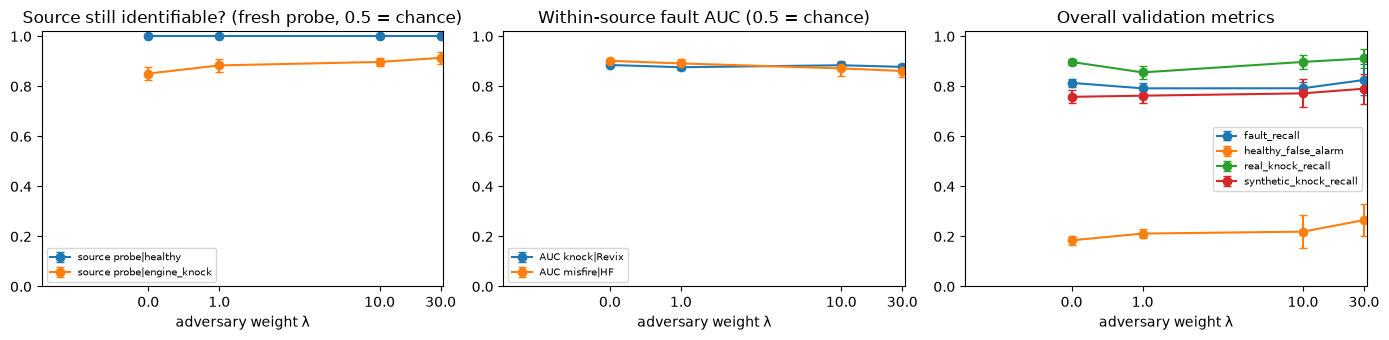

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
groups = {
    "Source still identifiable? (fresh probe, 0.5 = chance)": ["source probe|healthy", "source probe|engine_knock"],
    "Within-source fault AUC (0.5 = chance)": list(WITHIN_SOURCE),
    "Overall validation metrics": ["fault_recall", "healthy_false_alarm", "real_knock_recall", "synthetic_knock_recall"],
}
for ax, (title, cols) in zip(axes, groups.items()):
    for col in cols:
        g = adversarial.groupby("lambda")[col]
        ax.errorbar(ADV_LAMBDAS, g.mean(), yerr=g.std(), marker="o", capsize=3, label=col)
    ax.set(title=title, xlabel="adversary weight λ", ylim=(0, 1.02), xscale="symlog", xticks=ADV_LAMBDAS,
           xticklabels=ADV_LAMBDAS)
    ax.legend(fontsize=7)
plt.tight_layout()
save_fig("adversarial")
plt.show()

**Result (draft): adversarial training did not remove the source.** The adversary is partly fooled during training
(its accuracy falls from ≈ 1.0 at λ = 0 to ≈ 0.81), yet a fresh probe still identifies the source of healthy clips
**perfectly** at every λ, and identifies knock sources *better* as λ grows (≈ 0.85 → 0.91). Fault metrics and
within-source AUCs stay within seed-to-seed noise. Fooling one adversary is not the same as removing the
information — a known weakness of adversarial removal (Elazar & Goldberg, 2018, *Adversarial Removal of Demographic
Attributes from Text Data*).

**What this means:** the source fingerprint in these embeddings is too strong to train away with this data. One
plausible contributor (a hypothesis, not tested): Revix audio was recorded at 16 kHz, while Hugging Face and AudioSet
clips were resampled from 44.1/48 kHz, so their spectra may differ in ways unrelated to engines. The fix is in the
data — recordings where every class shares the same vehicles, microphone and pipeline — not in the model.

The λ = 0 runs also give a stability estimate: across 5 seeds, fault recall varies by ≈ ±0.02.

## 10. Stability across random seeds

The baseline and Experiment 2 differ by two validation clips in a single run. Here both are retrained with 10
random seeds (the seed changes the head's starting weights and the order of training batches).

**Selection rule, fixed before the test set is used:** the final configuration is the one with the higher mean
validation fault recall across seeds, among those whose mean false-alarm rate is at most 0.20.

In [28]:
STABILITY_SEEDS = range(10)
CONFIGS = {"Baseline": None, "Exp 2 (class weights)": class_weight}

rows = []
for seed in STABILITY_SEEDS:
    for name, weights in CONFIGS.items():
        proba, _, _ = train_head(X[tr], y[tr], X[va], y[va], class_weight=weights, seed=seed)
        rows.append({"config": name, "seed": seed, **val_metrics(proba(X[va]).argmax(1))})
stability = pd.DataFrame(rows)
stability["meets both targets"] = (stability["fault_recall"] >= 0.85) & (stability["healthy_false_alarm"] <= 0.20)
stability.to_csv(RESULTS_DIR / "seed_stability.csv", index=False)

cols = ["fault_recall", "healthy_false_alarm", "knock_recall", "misfire_recall"]
summary = stability.groupby("config")[cols].agg(["mean", "std"]).round(3)
summary["seeds meeting both targets"] = stability.groupby("config")["meets both targets"].sum()
display(summary)

paired = stability.pivot(index="seed", columns="config", values="fault_recall")
diff = paired["Exp 2 (class weights)"] - paired["Baseline"]
print(f"Exp 2 minus Baseline, fault recall: mean {diff.mean():+.3f}, "
      f"range {diff.min():+.3f} to {diff.max():+.3f}, higher in {(diff > 0).sum()} of {len(diff)} seeds")

means = stability.groupby("config")[cols].mean()
eligible = means[means["healthy_false_alarm"] <= 0.20]
FINAL_CONFIG = (eligible if len(eligible) else means)["fault_recall"].idxmax()
print("Final configuration:", FINAL_CONFIG)

/tmp/ipykernel_24615/1510516487.py:15: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  summary["seeds meeting both targets"] = stability.groupby("config")["meets both targets"].sum()


fault_recall        healthy_false_alarm         \
                              mean    std                mean    std   
config                                                                 
Baseline                     0.765  0.027               0.200  0.021   
Exp 2 (class weights)        0.847  0.017               0.196  0.030   

                      knock_recall        misfire_recall         \
                              mean    std           mean    std   
config                                                            
Baseline                     0.755  0.024          0.775  0.044   
Exp 2 (class weights)        0.713  0.017          0.981  0.030   

                      seeds meeting both targets  
                                                  
config                                            
Baseline                                       0  
Exp 2 (class weights)                          2

Exp 2 minus Baseline, fault recall: mean +0.082, range +0.008 to +0.125, higher in 10 of 10 seeds
Final configuration: Exp 2 (class weights)


## 11. Final evaluation on the test split (run once)

Both configurations are shown for comparison, but only the one selected above on validation is the final model
(trained with the notebook's default seed, as logged in the experiment table). `real_test` contains only real
knocks, so it gives knock recall only — it cannot measure false alarms.

,selected,fault_recall,knock_recall,misfire_recall,fault_detected,healthy_false_alarm,macro_f1,accuracy,real_knock_recall,synthetic_knock_recall,real_test_knock_recall,real_test_flagged_as_fault
Baseline,False,0.900,0.800,1.0,0.842,0.113,0.864,0.851,0.905,0.698,0.868,0.868
Exp 2 (class weights),True,0.906,0.812,1.0,0.861,0.113,0.862,0.857,0.905,0.721,0.868,0.868


test: 154 clips {'healthy': np.int64(53), 'engine_knock': np.int64(85), 'misfire': np.int64(16)}; real_test: 38 real knock clips


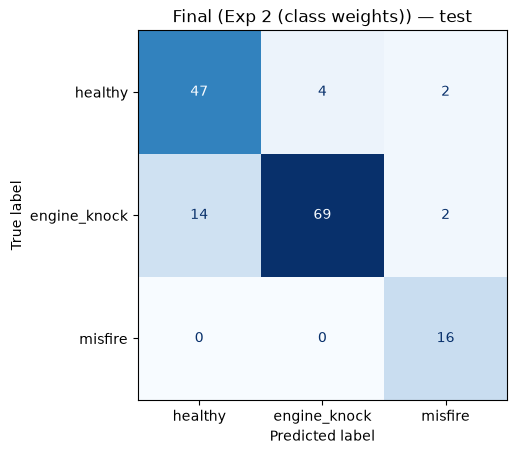

In [29]:
te, rt = split["test"], split["real_test"]
predictors = {"Baseline": baseline_proba, "Exp 2 (class weights)": exp2_proba}

final = {}
for name, predict in predictors.items():
    pred = predict(X[te]).argmax(1)
    knock, synth = y[te] == LABEL_TO_ID["engine_knock"], synthetic_flag[te]
    final[name] = {
        **evaluate(y[te], pred),
        "real_knock_recall": (pred[knock & ~synth] == LABEL_TO_ID["engine_knock"]).mean(),
        "synthetic_knock_recall": (pred[knock & synth] == LABEL_TO_ID["engine_knock"]).mean(),
        "real_test_knock_recall": (predict(X[rt]).argmax(1) == LABEL_TO_ID["engine_knock"]).mean(),
        "real_test_flagged_as_fault": (predict(X[rt]).argmax(1) != LABEL_TO_ID["healthy"]).mean(),
    }
final = pd.DataFrame(final).T
final.insert(0, "selected", final.index == FINAL_CONFIG)
final.to_csv(RESULTS_DIR / "final_test.csv")
display(final.round(3))
print(f"test: {len(te)} clips {dict(zip(LABELS, np.bincount(y[te])))}; real_test: {len(rt)} real knock clips")

ConfusionMatrixDisplay(confusion_matrix(y[te], predictors[FINAL_CONFIG](X[te]).argmax(1), labels=[0, 1, 2]),
                       display_labels=LABELS).plot(cmap="Blues", colorbar=False)
plt.title(f"Final ({FINAL_CONFIG}) — test")
save_fig("final_confusion")
plt.show()